# 10 · 생성형 AI 기반 신약 분자 설계 (De novo Design)
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑫ 생성형 AI 기반 신약 분자 설계

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/10_Generative_Molecular_Design.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① SMILES 생성모델로 **새 분자 샘플링** ② 생성 품질 평가(**유효성·고유성·신규성·QED·SA·다양성**) ③ **온도(temperature)** 가 창의성에 미치는 영향 ④ **생성 → 필터 → 평가(QSAR) 깔때기** ⑤ 목표 지향 설계(조건부 생성·강화학습 개념) |
| **모델** | `entropy/gpt2_zinc_87m` — ZINC 수백만 분자로 사전학습된 GPT-2 계열 SMILES 생성모델 |
| **실행 환경** | CPU 가능(약 10분) · GPU(T4) 권장 |

> 지금까지는 **있는 분자를 분석·예측**했습니다. 이제 AI 가 **세상에 없던 분자를 직접 그려냅니다.**
> 탐색 가능한 약물 유사 분자 공간은 약 **10^60개** — 사람이 다 뒤질 수 없으므로 AI 가 유망한 영역을 생성합니다.

In [1]:
%pip install -q rdkit koreanize-matplotlib transformers
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, time
import warnings; warnings.filterwarnings("ignore")
from rdkit import Chem, DataStructs, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Draw, Descriptors, Crippen, QED, rdFingerprintGenerator
from rdkit.Contrib.SA_Score import sascorer          # 합성 난이도 점수 (RDKit 기본 포함)
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
from transformers import GPT2LMHeadModel, AutoTokenizer
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ 준비 완료 — device:", device)

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료 — device: cpu


## 1. 분자 생성모델의 원리
SMILES 는 '화학의 언어'입니다. GPT 가 다음 **단어**를 예측하듯, 분자 생성모델은 다음 **원자·결합 기호**를 예측합니다.

```
<시작>  →  C  →  C  →  O  →  c  →  1  →  …  →  <끝>
         각 단계에서 "다음에 올 기호의 확률분포"를 계산하고 샘플링
```

| 생성 방식 | 대표 모델 | 특징 |
|---|---|---|
| **언어모델(자기회귀)** | MolGPT, ChemGPT, **gpt2_zinc** (이 예제) | SMILES/SELFIES 를 한 글자씩 생성, 간단하고 빠름 |
| **VAE / 잠재공간** | JT-VAE, ChemVAE | 연속 잠재공간에서 최적화·보간 가능 |
| **강화학습 최적화** | REINVENT 4 | 보상함수(활성·ADMET)로 생성을 유도 — 산업 표준 |
| **확산모델(3D)** | DiffSBDD, TargetDiff | 단백질 pocket 안에 맞는 3D 분자를 직접 생성 |
| **구조 기반 생성** | Chemistry42, Pocket2Mol | 결합부위 형상에 맞춰 설계 |

In [2]:
model_name = "entropy/gpt2_zinc_87m"              # ZINC 데이터베이스 사전학습 (약 87M 파라미터)
tok = AutoTokenizer.from_pretrained(model_name)
gen = GPT2LMHeadModel.from_pretrained(model_name).to(device).eval()
print(f"생성모델 로드 완료 — 파라미터 {sum(p.numel() for p in gen.parameters()):,}개, 어휘 {tok.vocab_size}개")

생성모델 로드 완료 — 파라미터 87,331,584개, 어휘 2707개


## 2. 새로운 분자 생성 (샘플링)
- `do_sample=True`: 확률분포에서 **무작위 추출** → 매번 다른 분자 (창의적)
- `temperature`: 높을수록 과감·다양, 낮을수록 보수적·안정
- `top_k`: 상위 k개 후보 중에서만 선택 → 이상한 기호 억제

In [3]:
def sample_molecules(n=200, temperature=1.0, top_k=30, seed=42, batch=100):
    torch.manual_seed(seed)
    out = []
    for i in range(0, n, batch):
        b = min(batch, n - i)
        bos = torch.tensor([[tok.bos_token_id]] * b).to(device)
        with torch.no_grad():
            g = gen.generate(bos, do_sample=True, max_length=64, temperature=temperature, top_k=top_k,
                             pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id)
        out += [s.strip() for s in tok.batch_decode(g, skip_special_tokens=True)]
    return out

t = time.time()
raw = sample_molecules(300)
print(f"{len(raw)}개 생성 ({time.time()-t:.0f}초)")
for s in raw[:5]: print("  ", s)

300개 생성 (17초)
   CCOC(=O)Nc1ccc(Br)cc1NC(=O)c1ccc(OC)c(N2CCNC2=O)c1
   N#CCC1CCN(c2nnc([C@@H]3CCc4n[nH]cc4C3)n2CC2CC2)CC1
   C[C@@](O)(Cn1c([C@@H]2CCCCO2)nnc1N1CCC(F)(F)CC1)c1ccsc1
   CCN(CCNC(=O)N[C@H]1CCOC12CCCC2)c1ccccc1C
   O=C(N[C@H]1C[C@H]2CC[C@@H]1N2CCOC1CCC1)c1cnc2[nH]ncc2c1


## 3. ⭐ 생성 품질 평가 — 생성모델의 표준 지표
| 지표 | 정의 | 좋은 값 |
|---|---|---|
| **유효성 Validity** | RDKit 으로 파싱되는 비율 (화학 문법이 맞는가) | 높을수록 좋음 (>90%) |
| **고유성 Uniqueness** | 유효 분자 중 중복 아닌 비율 | 높을수록 좋음 |
| **신규성 Novelty** | 학습·참조 데이터에 없던 분자 비율 | 높을수록 좋음 |
| **다양성 Diversity** | 생성 분자 쌍의 평균 (1 − Tanimoto 유사도) | 0.7~0.9 적정 |
| **QED** | 약물다움 종합 점수 (0~1) | 높을수록 좋음 |
| **SA score** | 합성 난이도 (1=쉬움, 10=어려움) | 낮을수록 좋음 (<4 권장) |

In [4]:
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def profile(smiles_list, ref_smiles=None):
    mols, canon = [], []
    for s in smiles_list:
        m = Chem.MolFromSmiles(s)
        if m is not None:
            mols.append(m); canon.append(Chem.MolToSmiles(m))
    validity = len(mols) / len(smiles_list)
    uniq = len(set(canon)) / max(1, len(canon))
    novelty = np.nan if ref_smiles is None else len(set(canon) - set(ref_smiles)) / max(1, len(set(canon)))
    # 다양성: 무작위 200개 쌍의 평균 거리
    fps = [morgan.GetFingerprint(m) for m in mols[:200]]
    sims = [DataStructs.TanimotoSimilarity(fps[i], fps[j]) for i in range(len(fps)) for j in range(i + 1, len(fps))]
    div = 1 - np.mean(sims) if sims else np.nan
    df = pd.DataFrame({"SMILES": canon,
                       "MW": [Descriptors.MolWt(m) for m in mols],
                       "logP": [Crippen.MolLogP(m) for m in mols],
                       "QED": [QED.qed(m) for m in mols],
                       "SA": [sascorer.calculateScore(m) for m in mols],
                       "HBD": [Descriptors.NumHDonors(m) for m in mols],
                       "HBA": [Descriptors.NumHAcceptors(m) for m in mols]}).drop_duplicates("SMILES")
    df["Lipinski"] = (df.MW <= 500) & (df.logP <= 5) & (df.HBD <= 5) & (df.HBA <= 10)
    stats = {"유효성": validity, "고유성": uniq, "신규성": novelty, "다양성": div,
             "QED 평균": df.QED.mean(), "SA 평균": df.SA.mean(), "Lipinski 통과율": df.Lipinski.mean()}
    return df, stats

# 참조(비교군): 실제 약물 유사 화합물 — BACE 데이터셋
ref = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv")["mol"]
ref_canon = set(Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in ref[:500] if Chem.MolFromSmiles(s))

gen_df, gen_stats = profile(raw, ref_canon)
pd.Series(gen_stats).round(3).to_frame("생성 분자")

,생성 분자
유효성,1.000
고유성,1.000
신규성,1.000
다양성,0.863
QED 평균,0.733
SA 평균,3.171
Lipinski 통과율,0.983


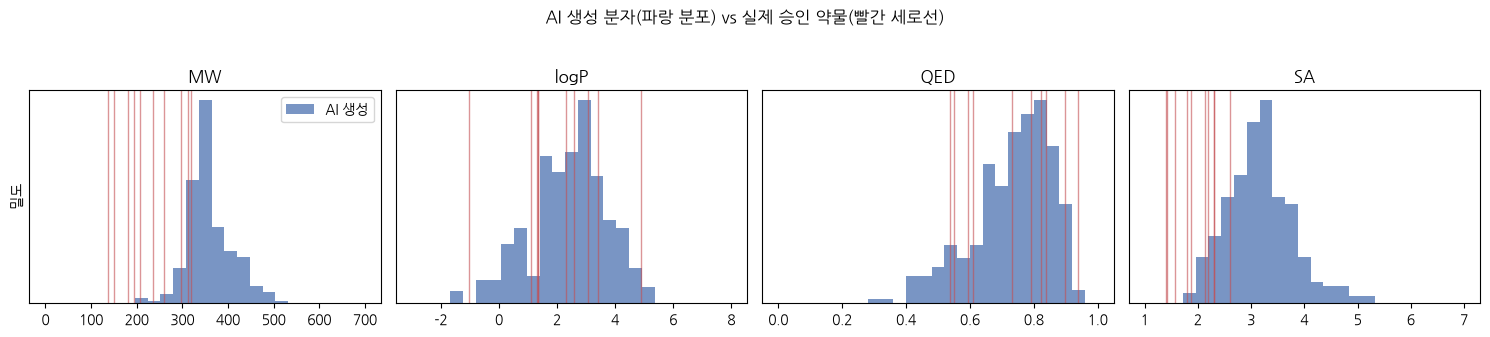

In [5]:
# 생성 분자 vs 실제 승인 약물의 물성 분포 비교
drugs = ["CC(=O)Oc1ccccc1C(=O)O", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C", "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
         "CC(=O)Nc1ccc(O)cc1", "COc1cc2c(cc1OC)C(=O)C(CC2)Cc1ccc(O)cc1", "CN(C)CCCN1c2ccccc2Sc2ccc(Cl)cc21",
         "CC(C)NCC(O)COc1cccc2ccccc12", "Cc1ccc(cc1)S(=O)(=O)NC(=O)NC1CCCCC1", "OC(=O)c1ccccc1O",
         "CCN(CC)CCNC(=O)c1ccc(N)cc1"]
dm = [Chem.MolFromSmiles(s) for s in drugs]
ref_df = pd.DataFrame({"MW": [Descriptors.MolWt(m) for m in dm], "logP": [Crippen.MolLogP(m) for m in dm],
                       "QED": [QED.qed(m) for m in dm], "SA": [sascorer.calculateScore(m) for m in dm]})

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, col, rng in zip(ax, ["MW", "logP", "QED", "SA"], [(0, 700), (-3, 8), (0, 1), (1, 7)]):
    a.hist(gen_df[col], bins=25, range=rng, color="#4C72B0", alpha=0.75, density=True, label="AI 생성")
    for v in ref_df[col]: a.axvline(v, color="#C44E52", alpha=0.6, lw=1)
    a.set_title(col); a.set_yticks([])
ax[0].legend(); ax[0].set_ylabel("밀도")
plt.suptitle("AI 생성 분자(파랑 분포) vs 실제 승인 약물(빨간 세로선)", y=1.04); plt.tight_layout(); plt.show()

## 4. 온도(temperature)의 효과 — 창의성과 품질의 거래
온도를 바꿔가며 유효성·다양성·QED 가 어떻게 변하는지 봅니다.

,temperature,유효성,고유성,신규성,다양성,QED 평균,SA 평균,Lipinski 통과율
0,0.7,1.000,1.0,1.0,0.848,0.758,3.197,0.987
1,1.0,1.000,1.0,1.0,0.868,0.739,3.155,0.987
2,1.3,0.980,1.0,1.0,0.878,0.715,3.120,0.973
3,1.6,0.973,1.0,1.0,0.879,0.701,3.179,0.966


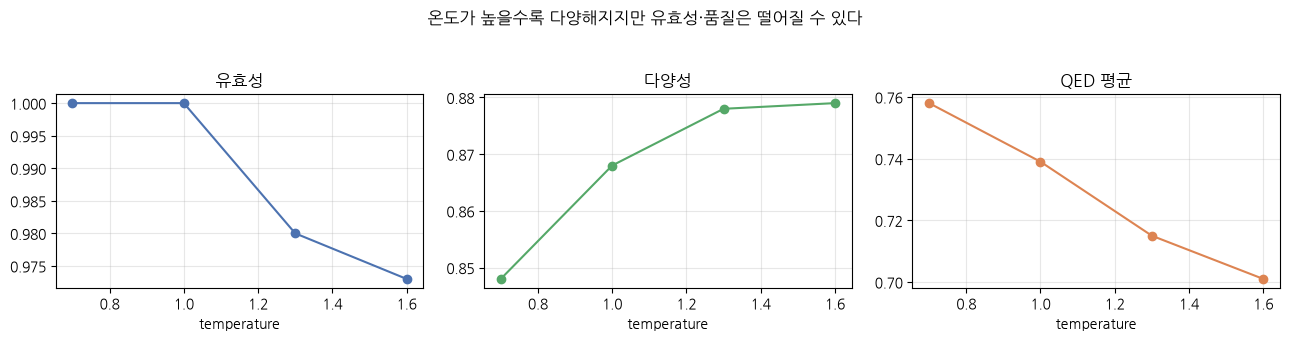

In [6]:
rows = []
for T in [0.7, 1.0, 1.3, 1.6]:
    s = sample_molecules(150, temperature=T, seed=1)
    _, st = profile(s, ref_canon)
    rows.append({"temperature": T, **{k: round(v, 3) for k, v in st.items()}})
temp_df = pd.DataFrame(rows)
display(temp_df)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, col, c in zip(ax, ["유효성", "다양성", "QED 평균"], ["#4C72B0", "#55A868", "#DD8452"]):
    a.plot(temp_df["temperature"], temp_df[col], "o-", color=c); a.set_xlabel("temperature"); a.set_title(col); a.grid(alpha=0.3)
plt.suptitle("온도가 높을수록 다양해지지만 유효성·품질은 떨어질 수 있다", y=1.05); plt.tight_layout(); plt.show()

## 5. ⭐ 생성 → 필터 깔때기 (Generate & Filter)
많이 만들고 **좋은 것만 남기는** 것이 실무 전략입니다.
1. 대량 생성 → 2. 유효성·중복 제거 → 3. 약물다움(Lipinski·QED) → 4. 합성 가능성(SA) → 5. 활성 예측(QSAR) → 6. 화학자 검토·합성

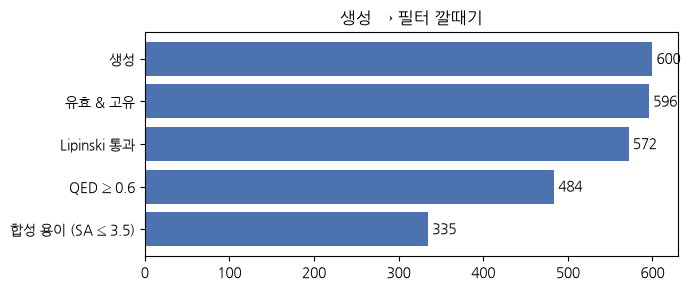

{'생성': 600, '유효 & 고유': 596, 'Lipinski 통과': 572, 'QED ≥ 0.6': 484, '합성 용이 (SA ≤ 3.5)': 335}


In [7]:
big = sample_molecules(600, temperature=1.0, seed=7)
df, _ = profile(big, ref_canon)
step = {"생성": len(big)}
d1 = df.copy();                                   step["유효 & 고유"] = len(d1)
d2 = d1[d1.Lipinski];                             step["Lipinski 통과"] = len(d2)
d3 = d2[d2.QED >= 0.6];                           step["QED ≥ 0.6"] = len(d3)
d4 = d3[d3.SA <= 3.5];                            step["합성 용이 (SA ≤ 3.5)"] = len(d4)
plt.figure(figsize=(7, 3)); plt.barh(list(step)[::-1], list(step.values())[::-1], color="#4C72B0")
for i, v in enumerate(list(step.values())[::-1]): plt.text(v, i, f" {v}", va="center")
plt.title("생성 → 필터 깔때기"); plt.tight_layout(); plt.show()
print({k: v for k, v in step.items()})

## 6. 목표 지향 설계 — QSAR 모델로 활성까지 평가
예제 06에서 만든 것과 같은 **BACE-1 QSAR 모델**로 생성 분자의 예상 활성을 매깁니다.
이것이 **생성형 AI + 예측형 AI 결합** 의 핵심 패턴입니다.

In [8]:
from sklearn.ensemble import RandomForestRegressor
bace = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv")
bace["m"] = bace["mol"].apply(Chem.MolFromSmiles); bace = bace[bace.m.notna()]
Xb = np.array([morgan.GetCountFingerprintAsNumPy(m) for m in bace.m], dtype=np.float32)
qsar = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(Xb, bace["pIC50"])

cand = d4.copy()
Xc = np.array([morgan.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in cand.SMILES], dtype=np.float32)
cand["예측 pIC50"] = qsar.predict(Xc)
# 적용 범위(AD): 학습 데이터와의 최근접 유사도 (예제 03)
ref_fps = [morgan.GetFingerprint(m) for m in bace.m]
cand["최근접유사도"] = [max(DataStructs.BulkTanimotoSimilarity(morgan.GetFingerprint(Chem.MolFromSmiles(s)), ref_fps)) for s in cand.SMILES]
top = cand.sort_values("예측 pIC50", ascending=False).head(8)
display(top[["SMILES", "MW", "logP", "QED", "SA", "예측 pIC50", "최근접유사도"]].round(2))
print("⚠️ 최근접 유사도가 낮으면(<0.3) QSAR 예측은 적용 범위 밖 — 신뢰도가 낮습니다.")

,SMILES,MW,logP,QED,SA,예측 pIC50,최근접유사도
361,Cc1cnc(C(=O)N(C)c2ccc3c(C)cc(=O)oc3c2)cc1C,322.36,3.39,0.68,2.45,7.09,0.19
24,Cc1ccccc1-n1ncc(C(=O)Nc2ccc3c(c2)C(=O)OC3)c1C(...,401.34,4.12,0.67,2.45,6.86,0.28
231,COC(=O)c1nc([C@@H]2CCCN2C(=O)Nc2cc3c(cc2Cl)OCC...,451.93,4.42,0.69,3.12,6.86,0.20
95,CC(=O)Nc1cc(F)c(S(=O)(=O)Nc2cc(Cl)ccc2N(C)C)cc1Cl,420.29,3.96,0.77,2.32,6.84,0.23
294,O=C(CN(Cc1cccs1)c1ccc2c(c1)OCCO2)NCc1cc(F)cc(F)c1,430.48,4.12,0.61,2.47,6.82,0.29
560,COc1cc(Br)ccc1C(=O)NCc1c(OC)cc(C)nc1O,381.23,2.81,0.83,2.34,6.81,0.24
517,COC(=O)c1cc(Cl)cc(C)c1NC(=O)CCc1ccc(-c2nn[nH]n...,399.84,3.19,0.62,2.28,6.72,0.25
7,Cc1nc(NC2CC2)sc1C(=O)NCc1ccc(S(C)(=O)=O)c(C(F)...,433.48,3.38,0.73,2.51,6.71,0.23


⚠️ 최근접 유사도가 낮으면(<0.3) QSAR 예측은 적용 범위 밖 — 신뢰도가 낮습니다.


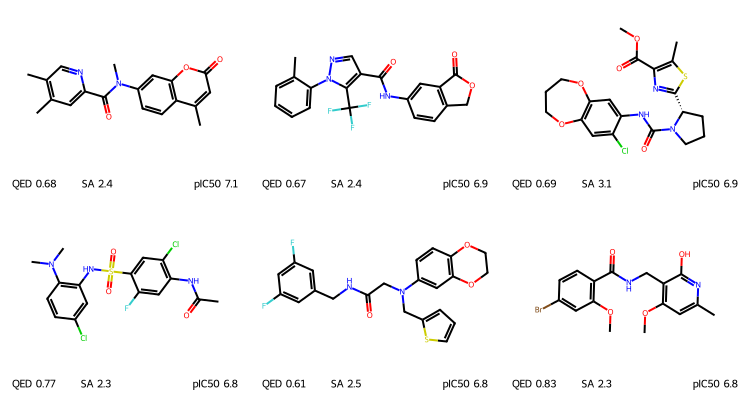

In [9]:
best = top.head(6)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in best.SMILES], molsPerRow=3, subImgSize=(250, 200),
                     legends=[f"QED {q:.2f} · SA {s:.1f} · 예측 pIC50 {p:.1f}" for q, s, p in zip(best.QED, best.SA, best["예측 pIC50"])])

## 7. 조건부 생성 — 원하는 성질을 노리기
간단한 방법은 **많이 생성하고 조건으로 거르기**(필터링)입니다. 실제 산업 도구는 아래 방식을 씁니다.

| 방법 | 설명 | 도구 |
|---|---|---|
| **조건 토큰** | "QED>0.8" 같은 조건을 입력 토큰으로 학습 | MolGPT |
| **강화학습** | 보상(활성·ADMET·SA)이 높은 분자를 더 자주 생성하도록 모델 갱신 | **REINVENT 4** (AstraZeneca, 오픈소스) |
| **유전 알고리즘** | 분자를 교배·돌연변이시켜 점수 최적화 | GraphGA, Crossover |
| **능동학습** | 생성 → 도킹·실험 → 모델 갱신 반복 | 산업 표준 워크플로우 |
| **구조 기반 확산모델** | 표적 pocket 3D 형상에 맞춰 생성 | DiffSBDD, TargetDiff |

In [10]:
# '조건 필터링'으로 의사-조건부 생성: 작고(MW<400) 적당한 지용성(1<logP<3)의 약물다운 분자
target = df[(df.MW < 400) & (df.logP.between(1, 3)) & (df.QED > 0.7) & (df.SA < 3.5)].sort_values("QED", ascending=False)
print(f"조건을 만족하는 생성 분자: {len(target)}개 / 전체 {len(df)}개 ({len(target)/len(df):.1%})")
display(target.head(5)[["SMILES", "MW", "logP", "QED", "SA"]].round(2))

조건을 만족하는 생성 분자: 132개 / 전체 596개 (22.1%)


,SMILES,MW,logP,QED,SA
590,O=C(NCCC(=O)N1CCCc2occc2C1)c1ccc(F)cc1,330.36,2.51,0.94,2.30
296,O=S(=O)(NCC1Oc2ccccc2O1)c1cccs1,297.36,1.82,0.93,2.50
315,Cc1c(C(=O)O)cc(CN2Cc3ncccc3N3CCC[C@@H]3C2)n1C,340.43,2.41,0.93,3.23
510,CC[C@@H](C)C(=O)N1CCC[C@H](NC(=O)c2cc3ccccc3nn...,340.43,2.40,0.93,3.06
473,Cc1nc(C)c(C(=O)N[C@@H]2CCN(CC(F)(F)F)C2)nc1C,316.33,1.77,0.92,3.02


## 8. 생성형 AI 신약개발의 현실 — 성과와 한계
| 구분 | 내용 |
|---|---|
| **성과** | Insilico Medicine 의 **ISM001-055**(특발성 폐섬유증, AI 로 타겟·분자 모두 발굴) 등 AI 설계 분자들이 임상에 진입. 전임상 단계 기간이 크게 단축되었다는 보고 |
| **한계 ①** | 생성 분자 대부분은 **합성 불가능하거나 특허·독성 문제**가 있음 → 화학자 검토 필수 |
| **한계 ②** | QSAR·도킹 **점수를 속이는(reward hacking)** 분자가 생성될 수 있음 → 다중 목적 최적화·적용 범위 확인 |
| **한계 ③** | 임상 성공률 개선 여부는 아직 데이터가 쌓이는 중 — **설계는 빨라졌지만 생물학의 불확실성은 그대로** |
| **실무 결론** | 생성형 AI = **아이디어 생성기**. 평가(예측·도킹·ADMET)와 전문가 판단, 실험 검증이 결합되어야 가치 |

## 🧪 LLM 코딩 과제
```
위 노트북의 sample_molecules() 와 profile() 함수를 사용해서 top_k 를 10, 30, 100, 그리고 top_p(nucleus sampling) 0.9 로
바꿔가며 유효성·고유성·다양성·QED 를 비교하는 표와 그래프를 만들어줘.
generate() 에 top_p 를 쓰려면 top_k=0 으로 두어야 한다는 점에 유의해줘.
```

In [11]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 & 현장 응용
- 생성모델은 SMILES 를 '언어'처럼 학습해 **새 분자를 샘플링** — 유효성·고유성·신규성·다양성으로 품질 평가
- **온도·top_k** 로 창의성과 품질의 균형 조절
- 핵심 패턴: **생성(Generative) → 필터(규칙) → 평가(예측형 AI·도킹) → 전문가·실험**
- 산업 현장: REINVENT(강화학습), 구조 기반 확산모델, 능동학습 루프
- **합성 가능성(SA, retrosynthesis AI)** 과 **특허 신규성** 검토가 실무의 관문

➡️ **다음 예제 11**: 직접 모델을 만들지 않고 **공개 파운데이션 모델·AI 툴을 그대로 활용**하는 방법